# Modelo de proyección PyG — Netflix (NFLX) · 2026–2030
Cifras en **millones de USD** (fuente: TIKR). Antes de empezar, sube `netflix_pyg.csv` al panel de archivos 📁 de Colab.

Ejecuta las celdas en orden con **Shift + Enter**. Las hipótesis se cambian **solo en la Celda 3**.

## Celda 1 · Cargar datos y comprobar que cuadran

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import os
# Usa el CSV local si lo has subido; si no, lo descarga directamente de GitHub
ruta = "netflix_pyg.csv" if os.path.exists("netflix_pyg.csv") else \
       "https://raw.githubusercontent.com/jangostoc/finanzas-con-ia/main/02-modelo-pyg-netflix/netflix_pyg.csv"
pyg = pd.read_csv(ruta, index_col="concepto")
f = pyg.loc   # atajo para leer filas

# Cada subtotal debe coincidir con la suma de sus partidas (tolerancia: redondeo)
cuadres = pd.DataFrame({
    "Beneficio bruto":  f["Ingresos totales"] + f["Coste de los bienes vendidos"] - f["Beneficio bruto"],
    "Opex totales":     f["Gastos de venta generales y administrativos"] + f["Gastos de I+D"] - f["Gastos operativos totales"],
    "Beneficio operat.":f["Beneficio bruto"] + f["Gastos operativos totales"] - f["Beneficio operativo"],
    "EBT incl.":        f["EBT excl. articulos inusuales"] + f["Articulos inusuales"] - f["EBT incl. articulos inusuales"],
    "Beneficio neto":   f["EBT incl. articulos inusuales"] + f["Gastos de impuestos"] - f["Beneficio operaciones continuadas"],
}).T.round(2)

print("✅ Todo cuadra" if (cuadres.abs() <= 0.02).all().all() else "⚠️ Hay descuadres: revisa la tabla")
cuadres

✅ Todo cuadra


,2021,2022,2023,2024,2025,LTM
Beneficio bruto,0.00,-0.01,0.0,0.01,0.00,0.00
Opex totales,-0.01,0.00,0.0,0.00,0.00,-0.01
Beneficio operat.,0.00,0.01,0.0,0.00,0.01,-0.00
EBT incl.,0.00,0.00,0.0,0.00,0.00,0.00
Beneficio neto,-0.01,0.00,0.0,0.00,-0.00,0.00


## Celda 2 · Ratios históricos (la base para fijar hipótesis)

In [2]:
ingresos = f["Ingresos totales"]

ratios = pd.DataFrame({
    "Crecimiento ingresos %": ingresos.pct_change() * 100,
    "Coste ventas % ingresos": -f["Coste de los bienes vendidos"] / ingresos * 100,
    "Margen bruto %":          f["Beneficio bruto"] / ingresos * 100,
    "SG&A % ingresos":         -f["Gastos de venta generales y administrativos"] / ingresos * 100,
    "I+D % ingresos":          -f["Gastos de I+D"] / ingresos * 100,
    "Margen operativo %":      f["Beneficio operativo"] / ingresos * 100,
    "Tipo impositivo %":       -f["Gastos de impuestos"] / f["EBT incl. articulos inusuales"] * 100,
    "Margen neto %":           f["Beneficio operaciones continuadas"] / ingresos * 100,
}).T.round(1)

ratios["LTM"] = ratios["LTM"].where(ratios.index != "Crecimiento ingresos %")  # LTM vs 2025 no es comparable
ratios

,2021,2022,2023,2024,2025,LTM
Crecimiento ingresos %,NaN,6.5,6.7,15.6,15.9,NaN
Coste ventas % ingresos,58.4,60.6,58.5,53.9,51.5,50.9
Margen bruto %,41.6,39.4,41.5,46.1,48.5,49.1
SG&A % ingresos,13.1,13.0,13.0,11.8,11.5,11.8
I+D % ingresos,7.7,8.6,7.9,7.5,7.5,7.7
Margen operativo %,20.9,17.8,20.6,26.7,29.5,29.7
Tipo impositivo %,12.4,14.7,12.9,12.6,13.7,17.2
Margen neto %,17.2,14.2,16.0,22.3,24.3,28.2


## Celda 3 · HIPÓTESIS ✏️ (lo único que se toca)
Escenario base ilustrativo. Cambia los números y vuelve a ejecutar las celdas 3, 4 y 5.

In [3]:
anios = [2026, 2027, 2028, 2029, 2030]

hipotesis = pd.DataFrame({
    #                         2026    2027    2028    2029    2030
    "Crecimiento ingresos %": [14.0,   12.0,   11.0,   10.0,    9.0],
    "Coste ventas % ingresos":[50.5,   50.0,   49.5,   49.0,   48.5],
    "SG&A % ingresos":        [11.5,   11.3,   11.1,   10.9,   10.7],
    "I+D % ingresos":         [ 7.5,    7.5,    7.5,    7.5,    7.5],
    "Gastos por intereses":   [-800,   -800,   -800,   -800,   -800],   # importe fijo, M USD
    "Ingresos por intereses": [ 300,    300,    300,    300,    300],   # importe fijo, M USD
    "Tipo impositivo %":      [14.0,   14.0,   14.0,   14.0,   14.0],
}, index=anios).T

hipotesis

,2026,2027,2028,2029,2030
Crecimiento ingresos %,14.0,12.0,11.0,10.0,9.0
Coste ventas % ingresos,50.5,50.0,49.5,49.0,48.5
SG&A % ingresos,11.5,11.3,11.1,10.9,10.7
I+D % ingresos,7.5,7.5,7.5,7.5,7.5
Gastos por intereses,-800.0,-800.0,-800.0,-800.0,-800.0
Ingresos por intereses,300.0,300.0,300.0,300.0,300.0
Tipo impositivo %,14.0,14.0,14.0,14.0,14.0


## Celda 4 · Proyección 2026–2030

In [4]:
h = hipotesis
proy = pd.DataFrame(index=pyg.index.drop(["Articulos inusuales", "EBT incl. articulos inusuales"]), columns=anios, dtype=float)

ingreso_previo = f["Ingresos totales"]["2025"]   # año base: último ejercicio cerrado
for a in anios:
    ing   = ingreso_previo * (1 + h.loc["Crecimiento ingresos %", a] / 100)
    cogs  = -ing * h.loc["Coste ventas % ingresos", a] / 100
    bruto = ing + cogs
    sga   = -ing * h.loc["SG&A % ingresos", a] / 100
    imasd = -ing * h.loc["I+D % ingresos", a] / 100
    opex  = sga + imasd
    ebit  = bruto + opex
    gi, ii = h.loc["Gastos por intereses", a], h.loc["Ingresos por intereses", a]
    ebt   = ebit + gi + ii
    imp   = -ebt * h.loc["Tipo impositivo %", a] / 100

    proy[a] = [ing, cogs, bruto, sga, imasd, opex, ebit, gi, ii, 0, 0, ebt, imp, ebt + imp]
    ingreso_previo = ing

# Unimos histórico (2021–2025) + proyección (2026–2030)
hist = pyg.drop(columns="LTM").drop(index=["Articulos inusuales", "EBT incl. articulos inusuales"])
hist.columns = hist.columns.astype(int)
modelo = pd.concat([hist, proy], axis=1)

margenes = pd.DataFrame({
    "Margen bruto %":     modelo.loc["Beneficio bruto"] / modelo.loc["Ingresos totales"] * 100,
    "Margen operativo %": modelo.loc["Beneficio operativo"] / modelo.loc["Ingresos totales"] * 100,
    "Margen neto %":      modelo.loc["Beneficio operaciones continuadas"] / modelo.loc["Ingresos totales"] * 100,
}).T.round(1)

pd.options.display.float_format = "{:,.0f}".format
display(modelo)
pd.options.display.float_format = None
margenes

,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
concepto,,,,,,,,,,
Ingresos totales,"29,698","31,616","33,723","39,001","45,183","51,509","57,690","64,036","70,439","76,779"
Coste de los bienes vendidos,"-17,333","-19,168","-19,715","-21,038","-23,275","-26,012","-28,845","-31,698","-34,515","-37,238"
Beneficio bruto,"12,365","12,447","14,008","17,962","21,908","25,497","28,845","32,338","35,924","39,541"
Gastos de venta generales y administrativos,"-3,897","-4,103","-4,378","-4,620","-5,190","-5,923","-6,519","-7,108","-7,678","-8,215"
Gastos de I+D,"-2,274","-2,711","-2,676","-2,925","-3,391","-3,863","-4,327","-4,803","-5,283","-5,758"
Gastos operativos totales,"-6,171","-6,814","-7,054","-7,545","-8,581","-9,787","-10,846","-11,911","-12,961","-13,974"
Beneficio operativo,"6,195","5,633","6,954","10,418","13,327","15,710","17,999","20,427","22,963","25,567"
Gastos por intereses,-766,-706,-700,-719,-777,-800,-800,-800,-800,-800
Ingresos por intereses e inversiones,8,60,281,294,295,300,300,300,300,300


,2021,2022,2023,2024,2025,2026,2027,2028,2029,2030
Margen bruto %,41.6,39.4,41.5,46.1,48.5,49.5,50.0,50.5,51.0,51.5
Margen operativo %,20.9,17.8,20.6,26.7,29.5,30.5,31.2,31.9,32.6,33.3
Margen neto %,17.2,14.2,16.0,22.3,24.3,25.4,26.1,26.8,27.4,28.1


## Celda 5 · Gráfico y exportar a Excel

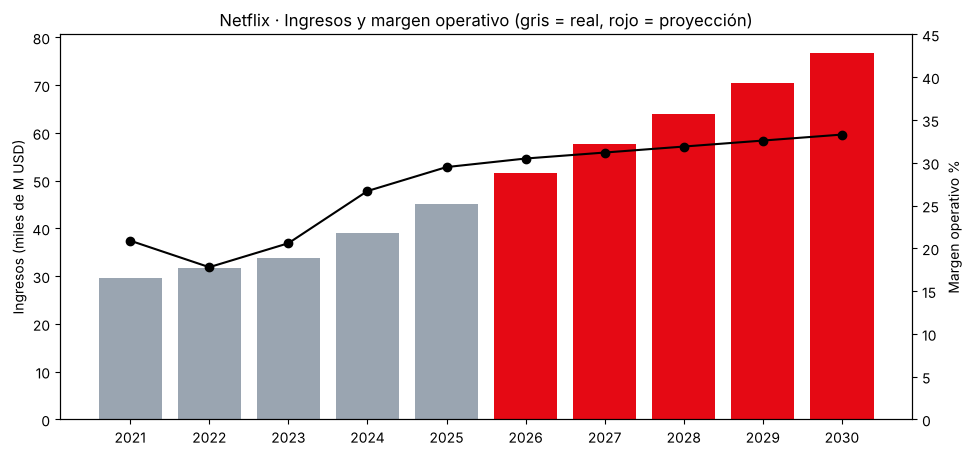

💾 Guardado modelo_netflix.xlsx (refresca el panel 📁 para verlo)


In [5]:
fig, ax1 = plt.subplots(figsize=(11, 5))
cols = ["#9aa5b1" if a <= 2025 else "#e50914" for a in modelo.columns]
ax1.bar(modelo.columns.astype(str), modelo.loc["Ingresos totales"] / 1000, color=cols)
ax1.set_ylabel("Ingresos (miles de M USD)")
ax1.set_title("Netflix · Ingresos y margen operativo (gris = real, rojo = proyección)")

ax2 = ax1.twinx()
ax2.plot(modelo.columns.astype(str), margenes.loc["Margen operativo %"], color="black", marker="o")
ax2.set_ylabel("Margen operativo %")
ax2.set_ylim(0, 45)
plt.savefig("grafico_modelo.png", dpi=150, bbox_inches="tight")
plt.show()

with pd.ExcelWriter("modelo_netflix.xlsx") as w:
    modelo.round(1).to_excel(w, sheet_name="PyG real + proyeccion")
    margenes.to_excel(w, sheet_name="Margenes")
    hipotesis.to_excel(w, sheet_name="Hipotesis")
    ratios.to_excel(w, sheet_name="Ratios historicos")
print("💾 Guardado modelo_netflix.xlsx (refresca el panel 📁 para verlo)")